In [1]:
!pip install GEOparse

Defaulting to user installation because normal site-packages is not writeable


#DICTIONARY ANNOTATION


In [2]:
import pandas as pd
import GEOparse
import os
import platform
import logging
import warnings

# Bỏ qua các cảnh báo không cần thiết
warnings.filterwarnings("ignore", category=SyntaxWarning)
logging.getLogger("GEOparse").setLevel(logging.CRITICAL)
warnings.simplefilter(action='ignore', category=pd.errors.SettingWithCopyWarning)

# --------------------------------------------------------------------------------

# --- Mapping miRNA ID to miRNA name
GEO_ID = "GSE106817"
dest_dir = "/content/"  # Thư mục đích để lưu file tải về (phù hợp nếu bạn đang dùng Google Colab)

# Tự động tải file từ GEO database về thư mục dest_dir (nếu chưa có) và đọc dữ liệu
print(f"Đang tiến hành tải và đọc dữ liệu {GEO_ID} từ GEO...")
gse = GEOparse.get_GEO(geo=GEO_ID, destdir=dest_dir)

# Trích xuất annotation
# Lấy bảng dữ liệu (table) từ platform (GPL) đầu tiên trong dataset
gpl_name = list(gse.gpls.keys())[0]
gene_anno = gse.gpls[gpl_name].table[["ID", "miRNA_ID_LIST"]].dropna()

# Thiết lập ID làm index
gene_anno.set_index("ID", inplace=True)
gene_anno.index.name = None

# Tạo dictionary để mapping
mapping_dict = gene_anno["miRNA_ID_LIST"].to_dict()

print("Gene annotation data:")
print(gene_anno.head())
print("Kích thước bảng:", gene_anno.shape)
print("-----------------------------------------------")

Đang tiến hành tải và đọc dữ liệu GSE106817 từ GEO...


Gene annotation data:
              miRNA_ID_LIST
MIMAT0000062  hsa-let-7a-5p
MIMAT0000063  hsa-let-7b-5p
MIMAT0000064  hsa-let-7c-5p
MIMAT0000065  hsa-let-7d-5p
MIMAT0000066  hsa-let-7e-5p
Kích thước bảng: (2565, 1)
-----------------------------------------------


#Expression data

In [3]:
import pandas as pd
import numpy as np

# --- 1. Load the Data ---
exprs_raw_1 = pd.read_csv("TCGA.BRCA.sampleMap_miRNA_HiSeq_gene.gz", sep="\t", index_col=0)
exprs_raw_2 = pd.read_csv("TCGA.BRCA.sampleMap_miRNA_GA_gene.gz", sep="\t", index_col=0)

# Make sure your mapping_dict is defined here before running the function!
# mapping_dict = {...}

# --- 2. Define a Processing Function ---
def process_tcga_dataset(exprs_raw, dataset_name):
    print(f"=== Processing: {dataset_name} ===")

    # Trước khi bỏ NA
    n_miRNA_raw = exprs_raw.shape[0]   # số hàng = số miRNA
    n_samples_raw = exprs_raw.shape[1] # số cột = số samples

    print("Before dropping NA:")
    print(f"Number of miRNA: {n_miRNA_raw}")
    print(f"Number of samples: {n_samples_raw}")

    # Sau khi bỏ NA
    exprs_clean = exprs_raw.dropna()   # bỏ hàng có NA
    exprs_clean.index.name = None
    exprs_clean = exprs_clean.T        # transpose: hàng = sample, cột = miRNA

    # Đổi tên cột (đảm bảo mapping_dict đã được tạo)
    # exprs_clean.rename(columns=mapping_dict, inplace=True)

    n_samples_clean = exprs_clean.shape[0]   # số hàng = số samples
    n_miRNA_clean = exprs_clean.shape[1]     # số cột = số miRNA

    print("After dropping NA:")
    print(f"Number of miRNA: {n_miRNA_clean}")
    print(f"Number of samples: {n_samples_clean}\n")

    return exprs_clean

# --- 3. Process Each Dataset Individually ---
# This will run your cleaning steps and print the stats for the HiSeq dataset
exprs_1 = process_tcga_dataset(exprs_raw_1, "HiSeq Dataset")

# This will run the exact same cleaning steps and print the stats for the GA dataset
exprs_2 = process_tcga_dataset(exprs_raw_2, "GA Dataset")

=== Processing: HiSeq Dataset ===
Before dropping NA:
Number of miRNA: 2238
Number of samples: 832
After dropping NA:
Number of miRNA: 225
Number of samples: 832

=== Processing: GA Dataset ===
Before dropping NA:
Number of miRNA: 2064
Number of samples: 333
After dropping NA:
Number of miRNA: 233
Number of samples: 333



#Clinical data

In [4]:
import pandas as pd

print("--- CHUẨN BỊ DỮ LIỆU EXPRESSION & CLINICAL CHO TẬP HISEQ ---")

# 1. ĐỊNH NGHĨA BIẾN CHO TẬP DỮ LIỆU HIỆN TẠI
# Chọn dataset bạn muốn thực hiện (ở đây là exprs_1)
exprs_target = exprs_1
clinical_file = "/content/TCGA.BRCA.sampleMap_BRCA_clinicalMatrix"
output_file = "TCGA_HiSeq_clinical.csv"

# 2. ĐỌC VÀ LỌC DỮ LIỆU LÂM SÀNG
clinical_df = pd.read_csv(clinical_file, sep="\t", index_col=0)

cols_to_keep = [
    "age_at_initial_pathologic_diagnosis",
    "days_to_death",
    "days_to_last_followup",
    "gender",
    "pathologic_stage",
    "sample_type",
    "vital_status",
    "days_to_new_tumor_event_after_initial_treatment"
]

# Chỉ giữ lại các cột thực sự có mặt trong file lâm sàng để tránh lỗi KeyError
cols_to_keep = [col for col in cols_to_keep if col in clinical_df.columns]
clinical_df = clinical_df[cols_to_keep]

# 3. GỘP DỮ LIỆU (MERGE)
# Lưu ý: Index của exprs_target và clinical_df phải khớp format với nhau
merged_df = exprs_target.merge(clinical_df, left_index=True, right_index=True, how="inner")

# 4. LƯU KẾT QUẢ
merged_df.to_csv(output_file)

print(f"Đã xử lý xong! Kích thước dữ liệu gộp: {merged_df.shape[0]} samples x {merged_df.shape[1]} features.")
print(f"File lưu tại: {output_file}\n")

--- CHUẨN BỊ DỮ LIỆU EXPRESSION & CLINICAL CHO TẬP HISEQ ---
Đã xử lý xong! Kích thước dữ liệu gộp: 832 samples x 233 features.
File lưu tại: TCGA_HiSeq_clinical.csv



In [5]:
import pandas as pd

print("--- CHUẨN BỊ DỮ LIỆU EXPRESSION & CLINICAL CHO TẬP HISEQ ---")

# 1. ĐỊNH NGHĨA BIẾN CHO TẬP DỮ LIỆU HIỆN TẠI
# Chọn dataset bạn muốn thực hiện (ở đây là exprs_1)
exprs_target = exprs_2
clinical_file = "/content/TCGA.BRCA.sampleMap_BRCA_clinicalMatrix"
output_file = "TCGA_GA_clinical.csv"

# 2. ĐỌC VÀ LỌC DỮ LIỆU LÂM SÀNG
clinical_df = pd.read_csv(clinical_file, sep="\t", index_col=0)

cols_to_keep = [
    "age_at_initial_pathologic_diagnosis",
    "days_to_death",
    "days_to_last_followup",
    "gender",
    "pathologic_stage",
    "sample_type",
    "vital_status",
    "days_to_new_tumor_event_after_initial_treatment"
]

# Chỉ giữ lại các cột thực sự có mặt trong file lâm sàng để tránh lỗi KeyError
cols_to_keep = [col for col in cols_to_keep if col in clinical_df.columns]
clinical_df = clinical_df[cols_to_keep]

# 3. GỘP DỮ LIỆU (MERGE)
# Lưu ý: Index của exprs_target và clinical_df phải khớp format với nhau
merged_df = exprs_target.merge(clinical_df, left_index=True, right_index=True, how="inner")

# 4. LƯU KẾT QUẢ
merged_df.to_csv(output_file)

print(f"Đã xử lý xong! Kích thước dữ liệu gộp: {merged_df.shape[0]} samples x {merged_df.shape[1]} features.")
print(f"File lưu tại: {output_file}\n")

--- CHUẨN BỊ DỮ LIỆU EXPRESSION & CLINICAL CHO TẬP HISEQ ---


Đã xử lý xong! Kích thước dữ liệu gộp: 333 samples x 241 features.
File lưu tại: TCGA_GA_clinical.csv



In [6]:
import pandas as pd

def prep_expression_with_type(exprs_df, clinical_df, output_filename):
    print(f"\n--- MATCHING CLINICAL & EXPRESSION: {output_filename} ---")

    # 1. Trích xuất cột sample_type từ dữ liệu lâm sàng
    sample_type = clinical_df[["sample_type"]]

    # 2. Merge expression và sample_type
    exprs_with_type = exprs_df.merge(sample_type, left_index=True, right_index=True, how="inner")

    # 3. Đổi tên và đưa cột 'type' lên đầu tiên
    exprs_with_type.rename(columns={"sample_type": "type"}, inplace=True)
    cols = ["type"] + [col for col in exprs_with_type.columns if col != "type"]
    exprs_with_type = exprs_with_type[cols]

    # 4. In thống kê các loại mẫu TRƯỚC khi mã hóa
    print("Number of categories in 'type' column BEFORE mapping:")
    print(exprs_with_type["type"].value_counts().to_string(header=False))
    print("-" * 47)

    # 5. Mã hóa: Normal = 0, Tumor/Metastatic = 1
    exprs_with_type["type"] = exprs_with_type["type"].map({
        "Primary Tumor": 1,
        "Solid Tissue Normal": 0,
        "Metastatic": 1
    }).fillna(0).astype(int)

    # 6. Xem trước dữ liệu và xuất file
    print("Expression data preview (first 5 rows, 3 columns):")
    print(exprs_with_type.iloc[:5, :3])

    exprs_with_type.to_csv(output_filename)
    print(f"-> Đã lưu file thành công tại: {output_filename}")

    return exprs_with_type

# ==========================================
# ÁP DỤNG CHO 2 DATASET CỦA BẠN
# ==========================================
# Lưu ý: Biến 'clinical_df' phải đang có sẵn trong bộ nhớ của bạn
# clinical_df = pd.read_csv("/content/TCGA.BRCA.sampleMap_BRCA_clinicalMatrix", sep="\t", index_col=0)

# 1. Xử lý tập HiSeq (exprs_1)
exprs_hiseq_final = prep_expression_with_type(
    exprs_df=exprs_1,
    clinical_df=clinical_df,
    output_filename="TCGA_HiSeq_Labelled.csv"
)

# 2. Xử lý tập GA (exprs_2)
exprs_ga_final = prep_expression_with_type(
    exprs_df=exprs_2,
    clinical_df=clinical_df,
    output_filename="TCGA_GA_Labelled.csv"
)


--- MATCHING CLINICAL & EXPRESSION: TCGA_HiSeq_Labelled.csv ---
Number of categories in 'type' column BEFORE mapping:
Primary Tumor          749
Solid Tissue Normal     76
Metastatic               7
-----------------------------------------------
Expression data preview (first 5 rows, 3 columns):
                 type  MIMAT0000764  MIMAT0000761
TCGA-OL-A66H-01     1      5.827901      4.187861
TCGA-3C-AALK-01     1      4.864784      3.515156
TCGA-AR-A1AH-01     1      5.897214      4.490978
TCGA-AC-A5EH-01     1      4.595051      3.436870
TCGA-EW-A2FW-01     1      6.562564      4.350379


-> Đã lưu file thành công tại: TCGA_HiSeq_Labelled.csv

--- MATCHING CLINICAL & EXPRESSION: TCGA_GA_Labelled.csv ---
Number of categories in 'type' column BEFORE mapping:
Primary Tumor          319
Solid Tissue Normal     14
-----------------------------------------------
Expression data preview (first 5 rows, 3 columns):
                 type  MIMAT0000764  MIMAT0000761
TCGA-BH-A0DQ-01     1      5.188213      3.965563
TCGA-A2-A0T4-01     1      3.585808      2.991280
TCGA-A8-A08T-01     1      3.875432      4.307739
TCGA-BH-A0W3-01     1      5.553630      4.974850
TCGA-AO-A03L-01     1      4.458875      4.786024


-> Đã lưu file thành công tại: TCGA_GA_Labelled.csv


#DE TCGA with AUC

In [7]:
# Cài đặt BiocManager và gói limma của R bên trong môi trường Colab
# (limma đã được cài sẵn ở môi trường này qua apt: r-bioc-limma; bỏ qua để tránh biên dịch lại)
# !R -e "if (!requireNamespace('BiocManager', quietly = TRUE)) install.packages('BiocManager', repos='https://cloud.r-project.org')"
# !R -e "BiocManager::install('limma', update=FALSE, ask=FALSE)"

TCGA_HiSeq Dataset


In [8]:
import os
import platform
import random
import numpy as np
import pandas as pd
import rpy2.robjects as ro
from rpy2.robjects import pandas2ri
from rpy2.robjects.conversion import localconverter
from sklearn.metrics import roc_auc_score

# Tương thích pandas 2.x với rpy2 3.4 (phương thức iteritems đã bị loại bỏ khỏi pandas)
if not hasattr(pd.DataFrame, "iteritems"):
    pd.DataFrame.iteritems = pd.DataFrame.items
    pd.Series.iteritems = pd.Series.items

# Cấu hình hiển thị pandas
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 10)

# -----------------------------
# 1. Thiết lập cấu hình hệ thống & Seed
# -----------------------------
np.random.seed(42)
random.seed(42)
ro.r("options(warn=-1)")

# Kiểm tra hệ điều hành để đặt thư mục làm việc (Thêm trường hợp Linux cho Colab)
current_sys = platform.system()
if current_sys == "Darwin":  # macOS
    os.chdir("/Users/trandon/Documents/Pan_Single/")
elif current_sys == "Windows":
    os.chdir("D:/Pancreatic Cancer/")
elif current_sys == "Linux":  # Google Colab
    os.chdir("/content/")
    print("Đang chạy trên môi trường Google Colab.")

# Đọc dữ liệu từ file đã upload
file_name = "TCGA_HiSeq_Labelled.csv"
if not os.path.exists(file_name):
    raise FileNotFoundError(f"Không tìm thấy file '{file_name}'. Hãy chắc chắn bạn đã upload file lên Colab (biểu tượng thư mục ở góc trái).")

df1 = pd.read_csv(file_name, sep=",", index_col=0)

# -----------------------------

# Ngưỡng lọc thống kê
pval_threshold = 0.05
logfc_threshold = 1

# -----------------------------
# 3. Hàm chạy Limma (Contrast động tương thích Colab)
# -----------------------------
def run_limma_two_groups(df):
    labels = df["type"].values
    unique_groups = sorted(list(set(labels)))
    if len(unique_groups) != 2:
        raise ValueError(f"Dữ liệu phải có chính xác 2 nhóm trong cột 'type'. Hiện có: {unique_groups}")

    expr = df.drop(columns=["type"]).T
    expr.index.name = "Gene"

    # Kích hoạt bộ chuyển đổi dữ liệu giữa Python và R
    with localconverter(ro.default_converter + pandas2ri.converter):
        expr_r = ro.conversion.py2rpy(expr)

    # Nạp thư viện limma trong R
    ro.r("library(limma)")
    ro.globalenv["group"] = ro.IntVector(labels)
    ro.globalenv["expr_r"] = expr_r

    # Thực thi mã R để phân tích biểu hiện sai khác (DE)
    ro.r("""
        group_factor <- factor(group)
        design <- model.matrix(~ 0 + group_factor)
        colnames(design) <- paste0('group', levels(group_factor))

        fit <- lmFit(expr_r, design)

        # Tự động tạo công thức tương phản dựa trên nhãn thực tế (Nhóm cao trừ Nhóm thấp)
        lvl1 <- levels(group_factor)[1]
        lvl2 <- levels(group_factor)[2]
        contrast_str <- paste0('group', lvl2, ' - group', lvl1)

        contrast.matrix <- makeContrasts(contrasts=contrast_str, levels=design)
        fit2 <- contrasts.fit(fit, contrast.matrix)
        fit2 <- eBayes(fit2)

        res <- topTable(fit2, coef=1, number=Inf, adjust='fdr')
    """)

    res = ro.r("res")
    with localconverter(ro.default_converter + pandas2ri.converter):
        res_df = ro.conversion.rpy2py(res)

    return res_df

# -----------------------------
# 4. Các hàm hỗ trợ lọc & tính toán chỉ số AUC
# -----------------------------
def filter_and_count(res_df):
    sig = res_df[(res_df["adj.P.Val"] < pval_threshold) & (res_df["logFC"].abs() > logfc_threshold)]
    return sig, len(sig)

def compute_auc(df, labels):
    aucs = {}
    expr = df.drop(columns=["type"])
    for gene in expr.columns:
        try:
            auc = roc_auc_score(labels, expr[gene])
            # Chuẩn hóa AUC luôn >= 0.5 để phản ánh khả năng phân tách của Marker ở cả 2 chiều
            auc = max(auc, 1 - auc)
            aucs[gene] = auc
        except Exception:
            aucs[gene] = np.nan
    return pd.Series(aucs, name="AUC")

# -----------------------------
# 5. Tiến trình thực thi chính (Main Workflow)
# -----------------------------
print("Đang chạy phân tích biểu hiện sai khác bằng Limma...")
res1 = run_limma_two_groups(df1)
sig1, count1 = filter_and_count(res1)
print(f"-> Số lượng miRNA có biểu hiện sai khác ý nghĩa (DE): {count1}")

print("Đang tính toán chỉ số AUC cho các biến...")
labels = df1["type"].values
auc_series = compute_auc(df1, labels)

# Hợp nhất bảng kết quả phân tích thống kê Limma với chỉ số AUC tương ứng
sig1_with_auc = sig1.merge(auc_series, left_index=True, right_index=True)

print("\n==== KẾT QUẢ: Các miRNA ý nghĩa sắp xếp theo chỉ số P-value điều chỉnh ====")
print(sig1_with_auc[["logFC", "adj.P.Val", "AUC"]].sort_values(by="adj.P.Val"))


Đang chạy trên môi trường Google Colab.
Đang chạy phân tích biểu hiện sai khác bằng Limma...


-> Số lượng miRNA có biểu hiện sai khác ý nghĩa (DE): 70
Đang tính toán chỉ số AUC cho các biến...



==== KẾT QUẢ: Các miRNA ý nghĩa sắp xếp theo chỉ số P-value điều chỉnh ====
                 logFC      adj.P.Val       AUC
MIMAT0000076  2.153060  4.287033e-114  0.979463
MIMAT0000250 -3.120842   4.591111e-99  0.987103
MIMAT0000261  2.828168   3.918950e-76  0.968219
MIMAT0000437 -2.558773   6.155109e-75  0.973197
MIMAT0022727  3.292028   2.383805e-63  0.954400
...                ...            ...       ...
MIMAT0006790 -1.360623   1.485050e-12  0.745649
MIMAT0000447 -1.010566   3.469244e-12  0.777082
MIMAT0000088 -1.137299   8.310263e-12  0.770433
MIMAT0000728  1.534874   1.190578e-08  0.741489
MIMAT0000264  1.193484   4.337207e-07  0.756300

[70 rows x 3 columns]


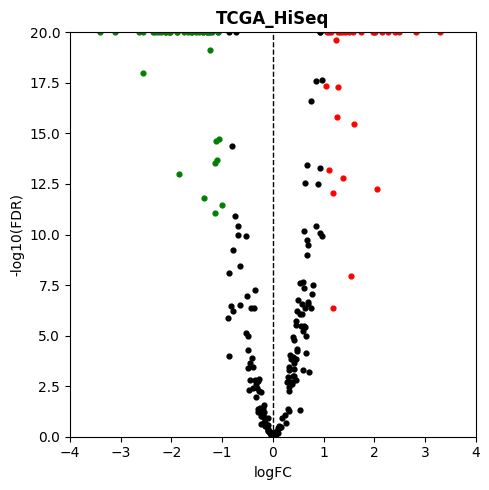

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# --- Volcano plot: TCGA_HiSeq (sig1_with_auc) ---
def plot_volcano(res_df, title, pval_threshold=0.05, logfc_threshold=1):
    logfc = res_df["logFC"]
    fdr   = res_df["adj.P.Val"]
    y     = (-np.log10(fdr)).clip(upper=20)  # giới hạn trục -log10(FDR) ở 20 như hình gốc

    up   = (logfc >  logfc_threshold) & (fdr < pval_threshold)   # đỏ: tăng biểu hiện
    down = (logfc < -logfc_threshold) & (fdr < pval_threshold)   # xanh: giảm biểu hiện
    ns   = ~(up | down)

    xmax = np.ceil(logfc.abs().max())

    plt.figure(figsize=(5, 5))
    plt.scatter(logfc[ns],   y[ns],   c="black", s=12)
    plt.scatter(logfc[up],   y[up],   c="red",   s=12)
    plt.scatter(logfc[down], y[down], c="green", s=12)
    plt.axvline(0, color="black", linestyle="--", linewidth=1)
    plt.title(title, fontweight="bold")
    plt.xlabel("logFC")
    plt.ylabel("-log10(FDR)")
    plt.xlim(-xmax, xmax)
    plt.ylim(0, 20)
    plt.tight_layout()
    plt.show()

plot_volcano(res1, "TCGA_HiSeq")


TCGA_GA Dataset

In [10]:
import os
import platform
import random
import numpy as np
import pandas as pd
import rpy2.robjects as ro
from rpy2.robjects import pandas2ri
from rpy2.robjects.conversion import localconverter
from sklearn.metrics import roc_auc_score

# Tương thích pandas 2.x với rpy2 3.4 (phương thức iteritems đã bị loại bỏ khỏi pandas)
if not hasattr(pd.DataFrame, "iteritems"):
    pd.DataFrame.iteritems = pd.DataFrame.items
    pd.Series.iteritems = pd.Series.items

# Cấu hình hiển thị pandas
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 10)

# -----------------------------
# 1. Thiết lập cấu hình hệ thống & Seed
# -----------------------------
np.random.seed(42)
random.seed(42)
ro.r("options(warn=-1)")

# Kiểm tra hệ điều hành để đặt thư mục làm việc (Thêm trường hợp Linux cho Colab)
current_sys = platform.system()
if current_sys == "Darwin":  # macOS
    os.chdir("/Users/trandon/Documents/Pan_Single/")
elif current_sys == "Windows":
    os.chdir("D:/Pancreatic Cancer/")
elif current_sys == "Linux":  # Google Colab
    os.chdir("/content/")
    print("Đang chạy trên môi trường Google Colab.")

# Đọc dữ liệu từ file đã upload
file_name = "TCGA_GA_Labelled.csv"
if not os.path.exists(file_name):
    raise FileNotFoundError(f"Không tìm thấy file '{file_name}'. Hãy chắc chắn bạn đã upload file lên Colab (biểu tượng thư mục ở góc trái).")

df2 = pd.read_csv(file_name, sep=",", index_col=0)

# -----------------------------

# Ngưỡng lọc thống kê
pval_threshold = 0.05
logfc_threshold = 1

# -----------------------------
# 3. Hàm chạy Limma (Contrast động tương thích Colab)
# -----------------------------
def run_limma_two_groups(df):
    labels = df["type"].values
    unique_groups = sorted(list(set(labels)))
    if len(unique_groups) != 2:
        raise ValueError(f"Dữ liệu phải có chính xác 2 nhóm trong cột 'type'. Hiện có: {unique_groups}")

    expr = df.drop(columns=["type"]).T
    expr.index.name = "Gene"

    # Kích hoạt bộ chuyển đổi dữ liệu giữa Python và R
    with localconverter(ro.default_converter + pandas2ri.converter):
        expr_r = ro.conversion.py2rpy(expr)

    # Nạp thư viện limma trong R
    ro.r("library(limma)")
    ro.globalenv["group"] = ro.IntVector(labels)
    ro.globalenv["expr_r"] = expr_r

    # Thực thi mã R để phân tích biểu hiện sai khác (DE)
    ro.r("""
        group_factor <- factor(group)
        design <- model.matrix(~ 0 + group_factor)
        colnames(design) <- paste0('group', levels(group_factor))

        fit <- lmFit(expr_r, design)

        # Tự động tạo công thức tương phản dựa trên nhãn thực tế (Nhóm cao trừ Nhóm thấp)
        lvl1 <- levels(group_factor)[1]
        lvl2 <- levels(group_factor)[2]
        contrast_str <- paste0('group', lvl2, ' - group', lvl1)

        contrast.matrix <- makeContrasts(contrasts=contrast_str, levels=design)
        fit2 <- contrasts.fit(fit, contrast.matrix)
        fit2 <- eBayes(fit2)

        res <- topTable(fit2, coef=1, number=Inf, adjust='fdr')
    """)

    res = ro.r("res")
    with localconverter(ro.default_converter + pandas2ri.converter):
        res_df = ro.conversion.rpy2py(res)

    return res_df

# -----------------------------
# 4. Các hàm hỗ trợ lọc & tính toán chỉ số AUC
# -----------------------------
def filter_and_count(res_df):
    sig = res_df[(res_df["adj.P.Val"] < pval_threshold) & (res_df["logFC"].abs() > logfc_threshold)]
    return sig, len(sig)

def compute_auc(df, labels):
    aucs = {}
    expr = df.drop(columns=["type"])
    for gene in expr.columns:
        try:
            auc = roc_auc_score(labels, expr[gene])
            # Chuẩn hóa AUC luôn >= 0.5 để phản ánh khả năng phân tách của Marker ở cả 2 chiều
            auc = max(auc, 1 - auc)
            aucs[gene] = auc
        except Exception:
            aucs[gene] = np.nan
    return pd.Series(aucs, name="AUC")

# -----------------------------
# 5. Tiến trình thực thi chính (Main Workflow)
# -----------------------------
print("Đang chạy phân tích biểu hiện sai khác bằng Limma...")
res2 = run_limma_two_groups(df2)
sig2, count1 = filter_and_count(res2)
print(f"-> Số lượng miRNA có biểu hiện sai khác ý nghĩa (DE): {count1}")

print("Đang tính toán chỉ số AUC cho các biến...")
labels = df2["type"].values
auc_series = compute_auc(df2, labels)

# Hợp nhất bảng kết quả phân tích thống kê Limma với chỉ số AUC tương ứng
sig2_with_auc = sig2.merge(auc_series, left_index=True, right_index=True)

print("\n==== KẾT QUẢ: Các miRNA ý nghĩa sắp xếp theo chỉ số P-value điều chỉnh ====")
print(sig2_with_auc[["logFC", "adj.P.Val", "AUC"]].sort_values(by="adj.P.Val"))


Đang chạy trên môi trường Google Colab.
Đang chạy phân tích biểu hiện sai khác bằng Limma...


-> Số lượng miRNA có biểu hiện sai khác ý nghĩa (DE): 88
Đang tính toán chỉ số AUC cho các biến...



==== KẾT QUẢ: Các miRNA ý nghĩa sắp xếp theo chỉ số P-value điều chỉnh ====
                 logFC     adj.P.Val       AUC
MIMAT0000097 -2.934549  2.930557e-17  0.995970
MIMAT0000250 -2.452009  2.930557e-17  0.983430
MIMAT0000076  1.524628  2.930557e-17  0.967085
MIMAT0000254 -2.276849  2.930557e-17  0.993506
MIMAT0000098 -2.620174  1.298470e-15  0.993059
...                ...           ...       ...
MIMAT0004550 -1.302371  6.400196e-04  0.825123
MIMAT0004784  1.382559  1.066231e-03  0.781460
MIMAT0003218  1.025340  1.884969e-03  0.808777
MIMAT0000433  1.183314  8.078488e-03  0.755262
MIMAT0000226  1.744454  1.419004e-02  0.733990

[88 rows x 3 columns]


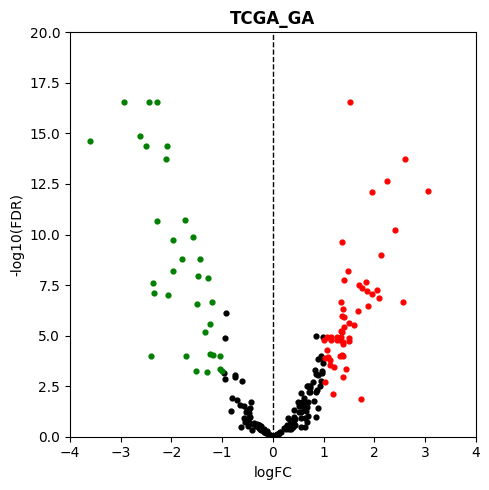

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# --- Volcano plot: TCGA_GA (sig2_with_auc) ---
def plot_volcano(res_df, title, pval_threshold=0.05, logfc_threshold=1):
    logfc = res_df["logFC"]
    fdr   = res_df["adj.P.Val"]
    y     = (-np.log10(fdr)).clip(upper=20)  # giới hạn trục -log10(FDR) ở 20 như hình gốc

    up   = (logfc >  logfc_threshold) & (fdr < pval_threshold)   # đỏ: tăng biểu hiện
    down = (logfc < -logfc_threshold) & (fdr < pval_threshold)   # xanh: giảm biểu hiện
    ns   = ~(up | down)

    xmax = np.ceil(logfc.abs().max())

    plt.figure(figsize=(5, 5))
    plt.scatter(logfc[ns],   y[ns],   c="black", s=12)
    plt.scatter(logfc[up],   y[up],   c="red",   s=12)
    plt.scatter(logfc[down], y[down], c="green", s=12)
    plt.axvline(0, color="black", linestyle="--", linewidth=1)
    plt.title(title, fontweight="bold")
    plt.xlabel("logFC")
    plt.ylabel("-log10(FDR)")
    plt.xlim(-xmax, xmax)
    plt.ylim(0, 20)
    plt.tight_layout()
    plt.show()

plot_volcano(res2, "TCGA_GA")



#Screening Survival in TCGA data



In [12]:
!pip install lifelines

Defaulting to user installation because normal site-packages is not writeable


TCGA_HiSeq Clinical


In [13]:
import pandas as pd
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test
import numpy as np

# 1. Đọc file clinical
df = pd.read_csv("TCGA_HiSeq_clinical.csv", index_col=0)

# 2. Xác định các cột miRNA an toàn
# Thay vì loại trừ các cột clinical, ta chủ động chọn các cột bắt đầu bằng "MIMAT" hoặc "hsa"
miRNA_cols = [col for col in df.columns if str(col).startswith("MIMAT") or str(col).startswith("hsa")]

print(f"Tổng số miRNA: {len(miRNA_cols)}")

# Chuẩn bị list lưu trữ results
results_list = []

# 3. Loop qua tất cả miRNA
for miRNA_of_interest in miRNA_cols:
    try:
        # Lấy dữ liệu cho miRNA này và dùng .copy() để tránh cảnh báo SettingWithCopyWarning
        df_miRNA = df[[miRNA_of_interest, "days_to_death", "days_to_last_followup", "vital_status"]].copy()

        # Đổi tên cột
        df_miRNA = df_miRNA.rename(columns={
            miRNA_of_interest: "expr",
            "days_to_death": "time",
            "vital_status": "status"
        })

        # Đảm bảo dữ liệu thời gian là dạng số (ép kiểu an toàn)
        df_miRNA["time"] = pd.to_numeric(df_miRNA["time"], errors='coerce')
        df_miRNA["days_to_last_followup"] = pd.to_numeric(df_miRNA["days_to_last_followup"], errors='coerce')

        # Thay thế missing survival time
        df_miRNA["time"] = df_miRNA["time"].fillna(df_miRNA["days_to_last_followup"])

        # Map status và ép kiểu về dạng int
        df_miRNA["status"] = df_miRNA["status"].map({"LIVING": 0, "DECEASED": 1})

        # Drop các hàng bị thiếu dữ liệu quan trọng để tránh lỗi toán học
        df_miRNA = df_miRNA.dropna(subset=["time", "status", "expr"])

        # Nếu sau khi drop NA không còn đủ data thì bỏ qua
        if df_miRNA.empty or len(df_miRNA) < 10:
            continue

        # Median split cutoff
        median_cutoff = df_miRNA["expr"].median()

        df_miRNA["group"] = df_miRNA["expr"].apply(lambda x: "High" if x >= median_cutoff else "Low")

        # Kaplan–Meier survival analysis masks
        high_mask = df_miRNA["group"] == "High"
        low_mask = df_miRNA["group"] == "Low"

        # Kiểm tra có đủ samples trong mỗi nhóm
        if high_mask.sum() < 5 or low_mask.sum() < 5:
            continue

        # Log-rank test
        results = logrank_test(
            df_miRNA.loc[high_mask, "time"], df_miRNA.loc[low_mask, "time"],
            event_observed_A=df_miRNA.loc[high_mask, "status"],
            event_observed_B=df_miRNA.loc[low_mask, "status"]
        )

        pval = results.p_value

        # Lưu kết quả
        results_list.append({
            "miRNA": miRNA_of_interest,
            "p_value": pval,
            "median_cutoff": median_cutoff,
            "n_high": high_mask.sum(),
            "n_low": low_mask.sum(),
            "n_total": len(df_miRNA)
        })

    except Exception as e:
        # Pass lỗi ẩn để code tiếp tục chạy với miRNA tiếp theo
        continue

# 4. Tạo và định dạng DataFrame kết quả
results_df = pd.DataFrame(results_list)

# Sort by p-value
results_df = results_df.sort_values("p_value")

print(f"\nTổng số miRNA tính toán thành công: {len(results_df)}")

# Lọc miRNA có p-value < 0.05
significant_miRNA_HiSeq = results_df[results_df["p_value"] < 0.05]

print(f"\n=== miRNA có p-value < 0.05 (tổng số: {len(significant_miRNA_HiSeq)}) ===")

# Trích xuất cột kết quả cần thiết
summary_df = significant_miRNA_HiSeq[["miRNA", "p_value"]].reset_index(drop=True)

# Đánh số index từ 1 cho dễ nhìn
summary_df.index = summary_df.index + 1

print(summary_df)

significant_list_HiSeq = summary_df["miRNA"].tolist()



Tổng số miRNA: 225



Tổng số miRNA tính toán thành công: 225

=== miRNA có p-value < 0.05 (tổng số: 60) ===
           miRNA   p_value
1   MIMAT0000077  0.000024
2   MIMAT0000281  0.000086
3   MIMAT0000433  0.000130
4   MIMAT0003249  0.000187
5   MIMAT0004911  0.000206
6   MIMAT0000099  0.000316
7   MIMAT0004614  0.000354
8   MIMAT0000259  0.000725
9   MIMAT0000752  0.000847
10  MIMAT0000440  0.000925
11  MIMAT0004549  0.001159
12  MIMAT0000090  0.001692
13  MIMAT0022834  0.001703
14  MIMAT0000710  0.001703
15  MIMAT0004502  0.002037
16  MIMAT0000732  0.002290
17  MIMAT0000753  0.002386
18  MIMAT0000258  0.002831
19  MIMAT0000617  0.003050
20  MIMAT0004694  0.003465
21  MIMAT0000449  0.004240
22  MIMAT0001635  0.004468
23  MIMAT0002871  0.004705
24  MIMAT0000443  0.005346
25  MIMAT0001343  0.005365
26  MIMAT0000680  0.007496
27  MIMAT0000728  0.008442
28  MIMAT0003239  0.009491
29  MIMAT0004559  0.010037
30  MIMAT0019731  0.010132
31  MIMAT0000432  0.011157
32  MIMAT0000279  0.012093
33  MIMAT0000069  0.0

TCGA_GA Clinical

In [14]:
import pandas as pd
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test
import numpy as np

# 1. Đọc file clinical
df = pd.read_csv("TCGA_GA_clinical.csv", index_col=0)

# 2. Xác định các cột miRNA an toàn
# Thay vì loại trừ các cột clinical, ta chủ động chọn các cột bắt đầu bằng "MIMAT" hoặc "hsa"
miRNA_cols = [col for col in df.columns if str(col).startswith("MIMAT") or str(col).startswith("hsa")]

print(f"Tổng số miRNA: {len(miRNA_cols)}")

# Chuẩn bị list lưu trữ results
results_list = []

# 3. Loop qua tất cả miRNA
for miRNA_of_interest in miRNA_cols:
    try:
        # Lấy dữ liệu cho miRNA này và dùng .copy() để tránh cảnh báo SettingWithCopyWarning
        df_miRNA = df[[miRNA_of_interest, "days_to_death", "days_to_last_followup", "vital_status"]].copy()

        # Đổi tên cột
        df_miRNA = df_miRNA.rename(columns={
            miRNA_of_interest: "expr",
            "days_to_death": "time",
            "vital_status": "status"
        })

        # Đảm bảo dữ liệu thời gian là dạng số (ép kiểu an toàn)
        df_miRNA["time"] = pd.to_numeric(df_miRNA["time"], errors='coerce')
        df_miRNA["days_to_last_followup"] = pd.to_numeric(df_miRNA["days_to_last_followup"], errors='coerce')

        # Thay thế missing survival time
        df_miRNA["time"] = df_miRNA["time"].fillna(df_miRNA["days_to_last_followup"])

        # Map status và ép kiểu về dạng int
        df_miRNA["status"] = df_miRNA["status"].map({"LIVING": 0, "DECEASED": 1})

        # Drop các hàng bị thiếu dữ liệu quan trọng để tránh lỗi toán học
        df_miRNA = df_miRNA.dropna(subset=["time", "status", "expr"])

        # Nếu sau khi drop NA không còn đủ data thì bỏ qua
        if df_miRNA.empty or len(df_miRNA) < 10:
            continue

        # Median split cutoff
        median_cutoff = df_miRNA["expr"].median()

        df_miRNA["group"] = df_miRNA["expr"].apply(lambda x: "High" if x >= median_cutoff else "Low")

        # Kaplan–Meier survival analysis masks
        high_mask = df_miRNA["group"] == "High"
        low_mask = df_miRNA["group"] == "Low"

        # Kiểm tra có đủ samples trong mỗi nhóm
        if high_mask.sum() < 5 or low_mask.sum() < 5:
            continue

        # Log-rank test
        results = logrank_test(
            df_miRNA.loc[high_mask, "time"], df_miRNA.loc[low_mask, "time"],
            event_observed_A=df_miRNA.loc[high_mask, "status"],
            event_observed_B=df_miRNA.loc[low_mask, "status"]
        )

        pval = results.p_value

        # Lưu kết quả
        results_list.append({
            "miRNA": miRNA_of_interest,
            "p_value": pval,
            "median_cutoff": median_cutoff,
            "n_high": high_mask.sum(),
            "n_low": low_mask.sum(),
            "n_total": len(df_miRNA)
        })

    except Exception as e:
        # Pass lỗi ẩn để code tiếp tục chạy với miRNA tiếp theo
        continue

# 4. Tạo và định dạng DataFrame kết quả
results_df = pd.DataFrame(results_list)

# Sort by p-value
results_df = results_df.sort_values("p_value")

print(f"\nTổng số miRNA tính toán thành công: {len(results_df)}")

# Lọc miRNA có p-value < 0.05
significant_miRNA_GA = results_df[results_df["p_value"] < 0.05]

print(f"\n=== miRNA có p-value < 0.05 (tổng số: {len(significant_miRNA_GA)}) ===")

# Trích xuất cột kết quả cần thiết
summary_df = significant_miRNA_GA[["miRNA", "p_value"]].reset_index(drop=True)

# Đánh số index từ 1 cho dễ nhìn
summary_df.index = summary_df.index + 1

print(summary_df)

significant_list_GA = summary_df["miRNA"].tolist()



Tổng số miRNA: 233



Tổng số miRNA tính toán thành công: 233

=== miRNA có p-value < 0.05 (tổng số: 28) ===
           miRNA   p_value
1   MIMAT0001536  0.000602
2   MIMAT0000063  0.002259
3   MIMAT0000728  0.003305
4   MIMAT0000693  0.004591
5   MIMAT0000733  0.005191
6   MIMAT0004485  0.007585
7   MIMAT0000763  0.008173
8   MIMAT0000446  0.010117
9   MIMAT0000064  0.010409
10  MIMAT0000754  0.013934
11  MIMAT0000097  0.014052
12  MIMAT0000761  0.014723
13  MIMAT0000441  0.014957
14  MIMAT0004911  0.017539
15  MIMAT0000088  0.023134
16  MIMAT0000759  0.024305
17  MIMAT0000255  0.024463
18  MIMAT0000266  0.025805
19  MIMAT0022727  0.027221
20  MIMAT0000447  0.027620
21  MIMAT0000425  0.031866
22  MIMAT0003258  0.034851
23  MIMAT0000101  0.035806
24  MIMAT0000450  0.040790
25  MIMAT0000682  0.040994
26  MIMAT0004801  0.042216
27  MIMAT0003239  0.042852
28  MIMAT0002174  0.045108


#INTERSECTION TCGA DATASET


In [15]:
# =====================================================================
# 1. FIX OVERLAPPING VARIABLES (If not already handled)
# =====================================================================
# To avoid `results_list` and `results_df` from GA overwriting HiSeq,
# we explicitly assign them to unique variables.
# Note: significant_miRNA_HiSeq and significant_miRNA_GA were already uniquely named in your code,
# but we ensure they are cleanly cast to lists/sets for intersection.

# Extract miRNAs from Survival Analysis
try:
    surv_hiseq_mirs = set(significant_miRNA_HiSeq['miRNA'])
except NameError:
    print("Warning: significant_miRNA_HiSeq not found. Please run the HiSeq Survival cell first.")
    surv_hiseq_mirs = set()

try:
    surv_ga_mirs = set(significant_miRNA_GA['miRNA'])
except NameError:
    print("Warning: significant_miRNA_GA not found. Please run the GA Survival cell first.")
    surv_ga_mirs = set()

# =====================================================================
# 2. CALCULATE INTERSECTIONS
# =====================================================================

# Extract miRNAs from DE TCGA with AUC Analysis
# (Using index names based on your Limma/AUC output structure)
try:
    # Attempt to load HiSeq DE results (named sig_with_auc or sig1_with_auc based on convention)
    if 'sig1_with_auc' in locals():
        de_hiseq_mirs = set(sig1_with_auc.index)
    elif 'sig_with_auc' in locals():
        de_hiseq_mirs = set(sig_with_auc.index)
    else:
        # Fallback to the generic 'sig' variable if AUC merge wasn't renamed
        de_hiseq_mirs = set(sig.index)
except NameError:
    print("Warning: HiSeq DE variables not found.")
    de_hiseq_mirs = set()

try:
    # Load GA DE results
    de_ga_mirs = set(sig2_with_auc.index)
except NameError:
    print("Warning: sig2_with_auc not found.")
    de_ga_mirs = set()

# --- Intersections ---
# 1. Intersection for HiSeq Dataset
intersect_hiseq = de_hiseq_mirs.intersection(surv_hiseq_mirs)
print(f"=== HISEQ INTERSECTION ===")
print(f"DE + AUC filtered miRNAs: {len(de_hiseq_mirs)}")
print(f"Survival filtered miRNAs: {len(surv_hiseq_mirs)}")
print(f"Intersection (HiSeq): {len(intersect_hiseq)} miRNAs")
print(list(intersect_hiseq))
print("-" * 50)

# 2. Intersection for GA Dataset
intersect_ga = de_ga_mirs.intersection(surv_ga_mirs)
print(f"=== GA INTERSECTION ===")
print(f"DE + AUC filtered miRNAs: {len(de_ga_mirs)}")
print(f"Survival filtered miRNAs: {len(surv_ga_mirs)}")
print(f"Intersection (GA): {len(intersect_ga)} miRNAs")
print(list(intersect_ga))
print("-" * 50)

# 3. Final Intersection (Common in BOTH HiSeq and GA)
final_intersection = intersect_hiseq.intersection(intersect_ga)
print(f"=== FINAL COMMON miRNAs (HiSeq ∩ GA) ===")
print(f"Total Common miRNAs: {len(final_intersection)}")
print(list(final_intersection))

# Save the final intersection to a CSV for future steps
if len(final_intersection) > 0:
    final_df = pd.DataFrame({"Common_miRNA": list(final_intersection)})
    final_df.to_csv("TCGA_Final_Intersection_miRNAs.csv", index=False)
    print("-> Successfully saved final intersecting miRNAs to 'TCGA_Final_Intersection_miRNAs.csv'")

=== HISEQ INTERSECTION ===
DE + AUC filtered miRNAs: 70
Survival filtered miRNAs: 60
Intersection (HiSeq): 30 miRNAs
['MIMAT0000318', 'MIMAT0000732', 'MIMAT0000710', 'MIMAT0001635', 'MIMAT0000090', 'MIMAT0002177', 'MIMAT0000753', 'MIMAT0022727', 'MIMAT0000752', 'MIMAT0004598', 'MIMAT0022834', 'MIMAT0000754', 'MIMAT0000617', 'MIMAT0003249', 'MIMAT0000728', 'MIMAT0006790', 'MIMAT0004559', 'MIMAT0004694', 'MIMAT0000263', 'MIMAT0000682', 'MIMAT0000281', 'MIMAT0004614', 'MIMAT0004494', 'MIMAT0000434', 'MIMAT0000680', 'MIMAT0000731', 'MIMAT0000432', 'MIMAT0000259', 'MIMAT0000433', 'MIMAT0000250']
--------------------------------------------------
=== GA INTERSECTION ===
DE + AUC filtered miRNAs: 88
Survival filtered miRNAs: 28
Intersection (GA): 16 miRNAs
['MIMAT0000266', 'MIMAT0022727', 'MIMAT0000064', 'MIMAT0000761', 'MIMAT0000088', 'MIMAT0000693', 'MIMAT0000446', 'MIMAT0000447', 'MIMAT0002174', 'MIMAT0004801', 'MIMAT0001536', 'MIMAT0000733', 'MIMAT0000754', 'MIMAT0000097', 'MIMAT0000682',

#INTERSECTION TCGA + GEO

In [16]:
# 1. Danh sách các MIMAT ID cuối cùng từ kết quả giao tập (Intersection)
final_mirnas = ['MIMAT0000754', 'MIMAT0022727', 'MIMAT0000682']

# 2. Ánh xạ (Map) MIMAT ID sang tên miRNA thông qua dictionary
mapped_mirnas = {mimat: mapping_dict.get(mimat, "Chưa tìm thấy trong annotation") for mimat in final_mirnas}

# ================= CODE BỔ SUNG: LƯU KẾT QUẢ VÀO FILE CSV =================

# 3. Chuyển đổi dictionary sang cấu trúc DataFrame của pandas
# Cột thứ nhất là MIMAT_ID, cột thứ hai là miRNA_Name tương ứng
df_mapped = pd.DataFrame(list(mapped_mirnas.items()), columns=['MIMAT_ID', 'miRNA_Name'])

# 4. Định nghĩa đường dẫn và tên file muốn lưu
# (Sử dụng đường dẫn thư mục '/content/' đồng bộ với biến dest_dir của bạn nếu chạy trên Colab)
output_file = os.path.join(dest_dir, "Mapped_Final_Intersection_miRNAs.csv")

# 5. Tiến hành lưu DataFrame thành file CSV
df_mapped.to_csv(output_file, index=False, encoding='utf-8')

# In thông báo kiểm tra kết quả
print("=== KẾT QUẢ MAPPING miRNA ===")
print(df_mapped)
print("-----------------------------------------------")
print(f"-> Đã lưu kết quả mapping thành công vào file: '{output_file}'")

=== KẾT QUẢ MAPPING miRNA ===
       MIMAT_ID       miRNA_Name
0  MIMAT0000754   hsa-miR-337-3p
1  MIMAT0022727  hsa-miR-1307-5p
2  MIMAT0000682  hsa-miR-200a-3p
-----------------------------------------------
-> Đã lưu kết quả mapping thành công vào file: '/content/Mapped_Final_Intersection_miRNAs.csv'


In [17]:
import pandas as pd

# 1. Đọc file TCGA (Giả sử cấu trúc như Hình 1: miRNA nằm ở cột 'miRNA_Name')
df_tcga = pd.read_csv('Mapped_Final_Intersection_miRNAs.csv')
set_tcga = set(df_tcga['miRNA_Name'].dropna())

# 2. Khai báo danh sách đường dẫn đến 4 file GEO của bạn
# (Hãy thay thế bằng tên file thực tế của bạn trên máy)
geo_files = [
    'GSE106817_Raw_Full_Probe.csv',
    'GSE113486_Raw_Full_Probe.csv',
    'GSE211692_Raw_Full_Probe.csv',
    'GSE73002_Raw_Full_Probe.csv'
]

# 3. Duyệt qua từng file GEO để lấy tên các cột (miRNA)
list_set_geo = []
for file in geo_files:
    # Mẹo nhỏ: Sử dụng nrows=1 để chỉ đọc dòng tiêu đề (header),
    # giúp code chạy cực nhanh mà không cần load file dữ liệu nặng vào RAM.
    df_geo = pd.read_csv(file, nrows=1)
    set_columns = set(df_geo.columns)
    list_set_geo.append(set_columns)


# --- XỬ LÝ LOGIC SO SÁNH ---

# LỰA CHỌN 1: Tìm miRNA xuất hiện ở TCGA và Ở CẢ 4 FILE GEO
common_all = set_tcga.copy()
for set_geo in list_set_geo:
    common_all = common_all.intersection(set_geo)

print(f"--- KẾT QUẢ LỰA CHỌN 1 ---")
print(f"Tìm thấy {len(common_all)} miRNA chung xuất hiện ở TCGA và TẤT CẢ 4 file GEO.")
print(list(common_all)[:10]) # Xem thử 10 phần tử đầu tiên


# LỰA CHỌN 2: Tìm miRNA xuất hiện ở TCGA và ÍT NHẤT 1 TRONG 4 FILE GEO
union_geo = set()
for set_geo in list_set_geo:
    union_geo = union_geo.union(set_geo) # Gộp tất cả miRNA của các file GEO lại

common_any = set_tcga.intersection(union_geo)

print(f"\n--- KẾT QUẢ LỰA CHỌN 2 ---")
print(f"Tìm thấy {len(common_any)} miRNA xuất hiện ở TCGA và ÍT NHẤT 1 file GEO.")
print(list(common_any)[:10])


# (Tùy chọn) Xuất kết quả ra file CSV mới để sử dụng
# pd.DataFrame(list(common_all), columns=['Common_miRNA']).to_csv('miRNA_chung_4_file.csv', index=False)

--- KẾT QUẢ LỰA CHỌN 1 ---
Tìm thấy 2 miRNA chung xuất hiện ở TCGA và TẤT CẢ 4 file GEO.
['hsa-miR-200a-3p', 'hsa-miR-337-3p']

--- KẾT QUẢ LỰA CHỌN 2 ---
Tìm thấy 3 miRNA xuất hiện ở TCGA và ÍT NHẤT 1 file GEO.
['hsa-miR-337-3p', 'hsa-miR-200a-3p', 'hsa-miR-1307-5p']


#VENN DIAGRAM (TCGA ∩ GSE73002 ∩ GSE113486)

TCGA ∩ GSE73002 ∩ GSE113486: ['hsa-miR-200a-3p', 'hsa-miR-337-3p']


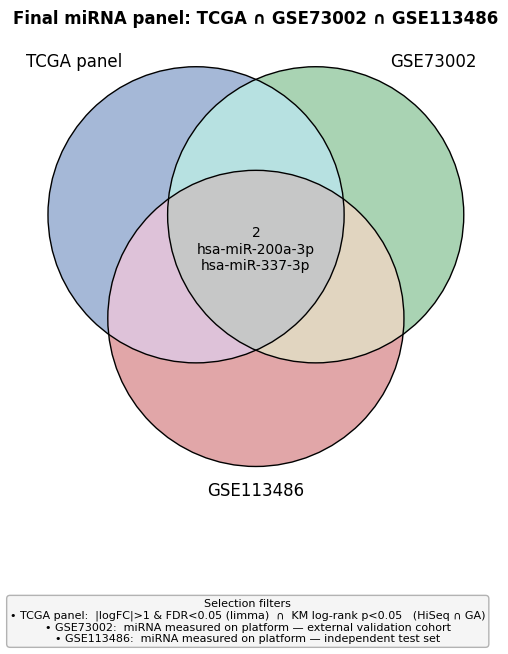

In [ ]:
!pip install -q matplotlib-venn

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib_venn import venn3, venn3_circles

# --- Panel cuối cùng (bỏ miR-1307-5p): 2 miRNA ---
final_panel = {"hsa-miR-200a-3p", "hsa-miR-337-3p"}

# 2 cohort GEO dùng kiểm định: GSE73002 (validation) + GSE113486 (test set)
g73  = set(pd.read_csv("GSE73002_Raw_Full_Probe.csv",  nrows=1).columns)
g113 = set(pd.read_csv("GSE113486_Raw_Full_Probe.csv", nrows=1).columns)

# Giới hạn coverage GEO trong phạm vi panel -> chỉ xét panel có đo được hay không
A = final_panel
B = final_panel & g73
C = final_panel & g113
print("TCGA ∩ GSE73002 ∩ GSE113486:", sorted(A & B & C))

# 7 vùng của Venn 3 tập
regions = {"100": A-B-C, "010": B-A-C, "001": C-A-B,
           "110": (A&B)-C, "101": (A&C)-B, "011": (B&C)-A, "111": A&B&C}

plt.figure(figsize=(6.5, 6.8))
v = venn3(subsets=(1,) * 7, set_labels=("TCGA panel", "GSE73002", "GSE113486"),
          set_colors=("#4C72B0", "#55A868", "#C44E52"), alpha=0.5)
venn3_circles(subsets=(1,) * 7, linewidth=1)

# Ghi số + tên miRNA; vùng rỗng để trống
for rid, members in regions.items():
    lbl = v.get_label_by_id(rid)
    if lbl is None:
        continue
    lbl.set_text("" if not members else f"{len(members)}\n" + "\n".join(sorted(members)))
    lbl.set_fontsize(10)

# Điều kiện lọc của từng tập
filt = ("Selection filters\n"
        "• TCGA panel:  |logFC|>1 & FDR<0.05 (limma)  ∩  KM log-rank p<0.05   (HiSeq ∩ GA)\n"
        "• GSE73002:  miRNA measured on platform — external validation cohort\n"
        "• GSE113486:  miRNA measured on platform — independent test set")
plt.gcf().text(0.5, 0.03, filt, ha="center", va="bottom", fontsize=8,
               bbox=dict(boxstyle="round", fc="#f5f5f5", ec="0.7"))

plt.title("Final miRNA panel: TCGA ∩ GSE73002 ∩ GSE113486", fontweight="bold")
plt.subplots_adjust(bottom=0.24, top=0.93)
plt.show()
